# Analysis of Student Skill Retention Level Prediction
## A Comparison of Decision Tree and KNN

**Research question:** Can students' Generative AI usage patterns, study habits, and academic factors predict whether their skill retention level is Low, Medium, or High?

This notebook follows the final project workflow: introduction, data loading, data cleaning, EDA, preprocessing, train/test split, model training, model evaluation, comparison, and conclusion.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (8, 5)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/ITE224/ai_student_impact_dataset.csv'

df = pd.read_csv(DATA_PATH)

print('Dataset loaded successfully!')
print('Dataset shape:', df.shape)


Mounted at /content/drive
Dataset loaded successfully!
Dataset shape: (50000, 16)


In [ ]:

df.head()


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  object 
 2   Year_of_Study               50000 non-null  object 
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  object 
 6   Prompt_Engineering_Skill    50000 non-null  object 
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  object 
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semester_GPA           500

In [ ]:
df.describe()

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


In [ ]:
print('Column names:')
print(df.columns.tolist())

Column names:
['Student_ID', 'Major_Category', 'Year_of_Study', 'Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Tool_Diversity', 'Paid_Subscription', 'Traditional_Study_Hours', 'Perceived_AI_Dependency', 'Institutional_Policy', 'Anxiety_Level_During_Exams', 'Post_Semester_GPA', 'Skill_Retention_Score', 'Burnout_Risk_Level']


## Data Cleaning

In [ ]:
# Check missing values
print('Missing values in each column:')
print(df.isnull().sum())

Missing values in each column:
Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64


In [ ]:
# Handle missing values if any exist
# Numeric columns: fill missing values with median
# Categorical columns: fill missing values with mode

numeric_cols_all = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols_all = df.select_dtypes(include=['object', 'bool']).columns

for col in numeric_cols_all:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols_all:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print('Missing values after cleaning:')
print(df.isnull().sum())

Missing values after cleaning:
Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64


In [ ]:
# Check duplicated rows
duplicate_count = df.duplicated().sum()
print('Number of duplicated rows:', duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates()
    print('Duplicated rows removed.')
else:
    print('No duplicated rows found.')

print('Dataset shape after duplicate check:', df.shape)

Number of duplicated rows: 0
No duplicated rows found.
Dataset shape after duplicate check: (50000, 16)


In [ ]:
# Check negative values in numeric columns
numeric_cols_all = df.select_dtypes(include=['int64', 'float64']).columns
negative_counts = (df[numeric_cols_all] < 0).sum()

print('Negative value count in numeric columns:')
print(negative_counts)

Negative value count in numeric columns:
Student_ID                    0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Tool_Diversity                0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
dtype: int64


In [ ]:
# Convert negative numeric values to positive if any exist
for col in numeric_cols_all:
    if (df[col] < 0).sum() > 0:
        df[col] = df[col].abs()

print('Negative values after correction:')
print((df[numeric_cols_all] < 0).sum())

Negative values after correction:
Student_ID                    0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Tool_Diversity                0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
dtype: int64


## Classification Target

The original `Skill_Retention_Score` is numeric. To make this a classification project, it is converted into three levels:

- **Low:** 0–60
- **Medium:** 60–90
- **High:** 90–100

This makes the target easier to classify and evaluate using accuracy score and confusion matrix.

In [ ]:
df['Skill_Retention_Level'] = pd.cut(
    df['Skill_Retention_Score'],
    bins=[0, 60, 90, 100],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

print('Skill Retention Level Distribution:')
print(df['Skill_Retention_Level'].value_counts())

print('\nPercentage:')
print((df['Skill_Retention_Level'].value_counts(normalize=True) * 100).round(2))


Skill Retention Level Distribution:
Skill_Retention_Level
Medium    36264
High       7724
Low        6012
Name: count, dtype: int64

Percentage:
Skill_Retention_Level
Medium    72.53
High      15.45
Low       12.02
Name: proportion, dtype: float64


### EDA Visualization 1: Pie Chart - Skill Retention Level Distribution

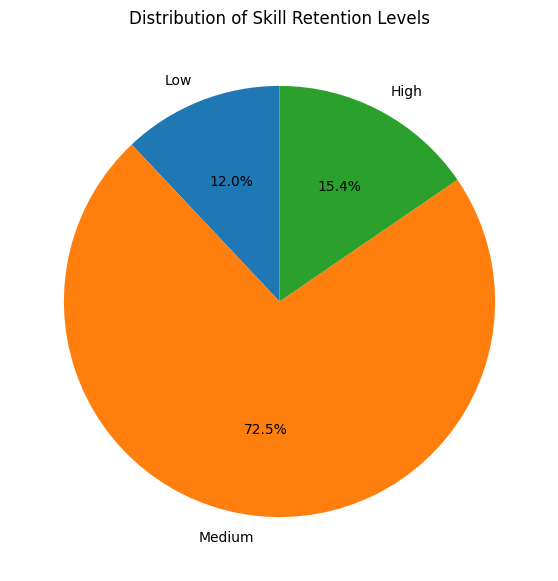

,count
Skill_Retention_Level,
Low,6012
Medium,36264
High,7724


In [ ]:
level_counts = df['Skill_Retention_Level'].value_counts().reindex(['Low', 'Medium', 'High'])

plt.figure(figsize=(7, 7))
plt.pie(
    level_counts,
    labels=level_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Distribution of Skill Retention Levels')
plt.show()

level_counts

### EDA Visualization 2: Bar Graph - Average Skill Retention Score by Prompt Engineering Skill

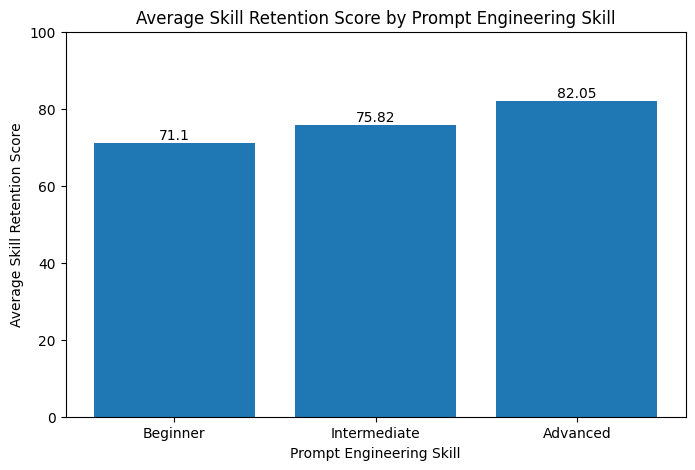

,Skill_Retention_Score
Prompt_Engineering_Skill,
Beginner,71.10
Intermediate,75.82
Advanced,82.05


In [ ]:
skill_order = ['Beginner', 'Intermediate', 'Advanced']

avg_skill_by_prompt = df.groupby(
    'Prompt_Engineering_Skill'
)['Skill_Retention_Score'].mean().reindex(skill_order)

plt.figure(figsize=(8, 5))
plt.bar(avg_skill_by_prompt.index, avg_skill_by_prompt.values)
plt.title('Average Skill Retention Score by Prompt Engineering Skill')
plt.xlabel('Prompt Engineering Skill')
plt.ylabel('Average Skill Retention Score')
plt.ylim(0, 100)

for i, value in enumerate(avg_skill_by_prompt.values):
    plt.text(i, value + 1, round(value, 2), ha='center')

plt.show()

avg_skill_by_prompt.round(2)

### EDA Visualization 3: Scatter Plot - Weekly GenAI Hours vs Skill Retention Score

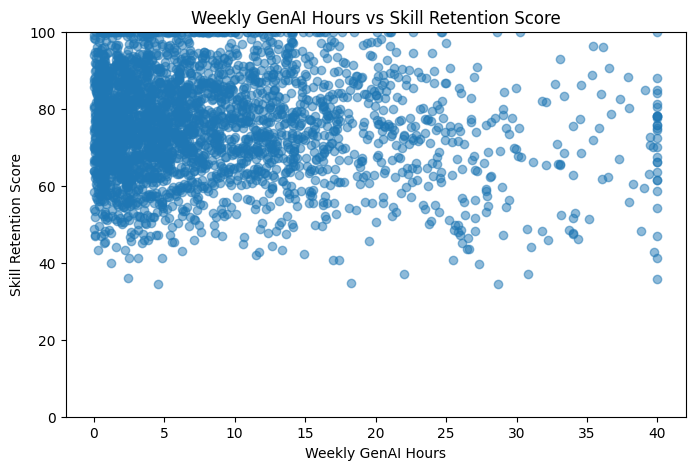

In [ ]:
# Use a sample for clearer plotting and faster rendering
plot_sample = df.sample(n=min(3000, len(df)), random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(
    plot_sample['Weekly_GenAI_Hours'],
    plot_sample['Skill_Retention_Score'],
    alpha=0.5
)
plt.title('Weekly GenAI Hours vs Skill Retention Score')
plt.xlabel('Weekly GenAI Hours')
plt.ylabel('Skill Retention Score')
plt.ylim(0, 100)
plt.show()

### EDA Visualization 4: Line Graph - Average Skill Retention Score by Year of Study

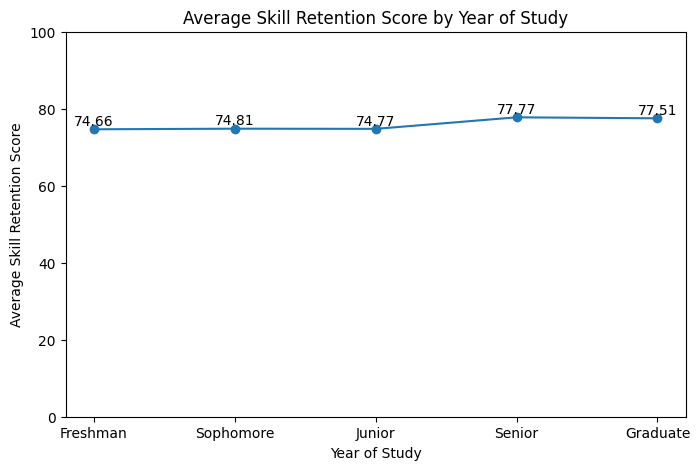

,Skill_Retention_Score
Year_of_Study,
Freshman,74.66
Sophomore,74.81
Junior,74.77
Senior,77.77
Graduate,77.51


In [ ]:
year_order = ['Freshman', 'Sophomore', 'Junior', 'Senior', 'Graduate']

avg_skill_by_year = df.groupby(
    'Year_of_Study'
)['Skill_Retention_Score'].mean().reindex(year_order)

plt.figure(figsize=(8, 5))
plt.plot(avg_skill_by_year.index, avg_skill_by_year.values, marker='o')
plt.title('Average Skill Retention Score by Year of Study')
plt.xlabel('Year of Study')
plt.ylabel('Average Skill Retention Score')
plt.ylim(0, 100)

for i, value in enumerate(avg_skill_by_year.values):
    plt.text(i, value + 1, round(value, 2), ha='center')

plt.show()

avg_skill_by_year.round(2)

## Features and Target

`Student_ID` is removed because it is only an identifier.

`Post_Semester_GPA`, `Skill_Retention_Score`, and `Burnout_Risk_Level` are not used as input features because they are outcome/result columns and may cause data leakage.

In [ ]:
target = 'Skill_Retention_Level'

feature_cols = [
    'Major_Category',
    'Year_of_Study',
    'Pre_Semester_GPA',
    'Weekly_GenAI_Hours',
    'Primary_Use_Case',
    'Prompt_Engineering_Skill',
    'Tool_Diversity',
    'Paid_Subscription',
    'Traditional_Study_Hours',
    'Perceived_AI_Dependency',
    'Institutional_Policy',
    'Anxiety_Level_During_Exams'
]

X = df[feature_cols]
y = df[target]

print('Feature shape:', X.shape)
print('Target shape:', y.shape)
print('\nFeatures used:')
print(feature_cols)
print('\nTarget distribution:')
print(y.value_counts())

Feature shape: (50000, 12)
Target shape: (50000,)

Features used:
['Major_Category', 'Year_of_Study', 'Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Tool_Diversity', 'Paid_Subscription', 'Traditional_Study_Hours', 'Perceived_AI_Dependency', 'Institutional_Policy', 'Anxiety_Level_During_Exams']

Target distribution:
Skill_Retention_Level
Medium    36264
High       7724
Low        6012
Name: count, dtype: int64


### Using Just a Sample for Faster KNN Training

KNN can be slow on large datasets. This notebook uses a 20,000-row stratified sample for faster execution. The original dataset has 50,000 rows, but 20,000 rows is still enough for the final project demonstration.

In [ ]:
USE_SAMPLE_FOR_SPEED = False
SAMPLE_SIZE = 20000

if USE_SAMPLE_FOR_SPEED and len(df) > SAMPLE_SIZE:
    modeling_df = df.groupby(target, group_keys=False).apply(
        lambda x: x.sample(
            n=max(1, int(SAMPLE_SIZE * len(x) / len(df))),
            random_state=42
        )
    ).copy()
else:
    modeling_df = df.copy()

print('Modeling dataset shape:', modeling_df.shape)
print('Modeling target distribution:')
print(modeling_df[target].value_counts())

X = modeling_df[feature_cols]
y = modeling_df[target]

Modeling dataset shape: (50000, 17)
Modeling target distribution:
Skill_Retention_Level
Medium    36264
High       7724
Low        6012
Name: count, dtype: int64


## Numeric and Categorical Features

In [ ]:
numeric_features = X.select_dtypes(include=['int64', 'float64', 'bool']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)

Numeric features: ['Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Tool_Diversity', 'Paid_Subscription', 'Traditional_Study_Hours', 'Perceived_AI_Dependency', 'Anxiety_Level_During_Exams']
Categorical features: ['Major_Category', 'Year_of_Study', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Institutional_Policy']


## Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)

print('y_train distribution:')
print(y_train.value_counts())

print('y_test distribution:')
print(y_test.value_counts())

X_train shape: (40000, 12)
X_test shape: (10000, 12)
y_train distribution:
Skill_Retention_Level
Medium    29011
High       6179
Low        4810
Name: count, dtype: int64
y_test distribution:
Skill_Retention_Level
Medium    7253
High      1545
Low       1202
Name: count, dtype: int64


## Preprocessing

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

## Model Training

Models used:

1. Baseline Model
2. Decision Tree Classifier
3. KNN Classifier

In [ ]:
baseline_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=20,
        random_state=42
    ))
])

knn_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(
        n_neighbors=11
    ))
])

baseline_model.fit(X_train, y_train)
decision_tree_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)

print('Classification models trained successfully!')

Classification models trained successfully!


## Predictions and Evaluation

In [ ]:
baseline_pred = baseline_model.predict(X_test)
dt_pred = decision_tree_model.predict(X_test)
knn_pred = knn_model.predict(X_test)

def evaluate_classification_model(model_name, y_true, y_pred):
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred)
    }

results = pd.DataFrame([
    evaluate_classification_model('Baseline', y_test, baseline_pred),
    evaluate_classification_model('Decision Tree Classifier', y_test, dt_pred),
    evaluate_classification_model('KNN Classifier', y_test, knn_pred)
])

results['Accuracy (%)'] = results['Accuracy'] * 100
results['Balanced Accuracy (%)'] = results['Balanced Accuracy'] * 100
results = results.sort_values(by='Accuracy', ascending=False)

results

,Model,Accuracy,Balanced Accuracy,Accuracy (%),Balanced Accuracy (%)
1,Decision Tree Classifier,0.7373,0.409379,73.73,40.937862
0,Baseline,0.7253,0.333333,72.53,33.333333
2,KNN Classifier,0.7157,0.377689,71.57,37.768854


In [ ]:
print('Decision Tree Classification Report')
print(classification_report(y_test, dt_pred, zero_division=0))

Decision Tree Classification Report
              precision    recall  f1-score   support

        High       0.56      0.22      0.31      1545
         Low       0.79      0.05      0.09      1202
      Medium       0.75      0.96      0.84      7253

    accuracy                           0.74     10000
   macro avg       0.70      0.41      0.42     10000
weighted avg       0.72      0.74      0.67     10000



In [ ]:
print('KNN Classification Report')
print(classification_report(y_test, knn_pred, zero_division=0))

KNN Classification Report
              precision    recall  f1-score   support

        High       0.44      0.14      0.21      1545
         Low       0.36      0.04      0.08      1202
      Medium       0.74      0.95      0.83      7253

    accuracy                           0.72     10000
   macro avg       0.51      0.38      0.37     10000
weighted avg       0.64      0.72      0.64     10000



## Final Visualization 1 - Model Accuracy Comparison

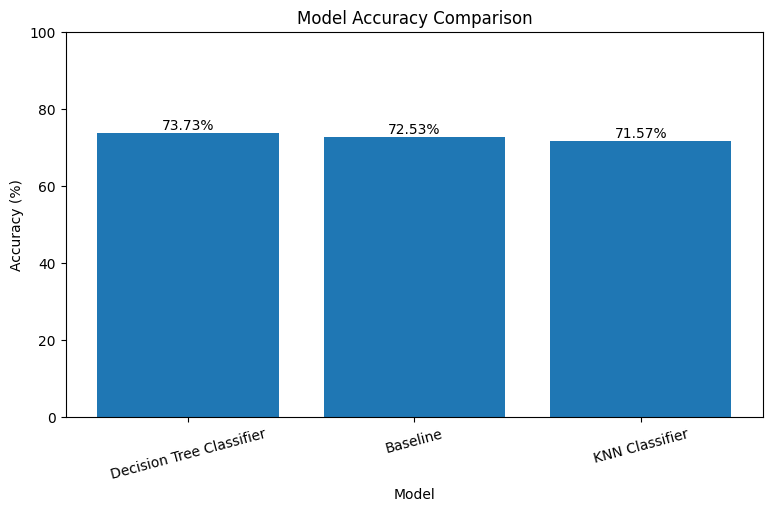

In [ ]:
plt.figure(figsize=(9, 5))
plt.bar(results['Model'], results['Accuracy (%)'])
plt.title('Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.xticks(rotation=15)

for i, value in enumerate(results['Accuracy (%)']):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.show()

## Final Visualization 2 - Confusion Matrices

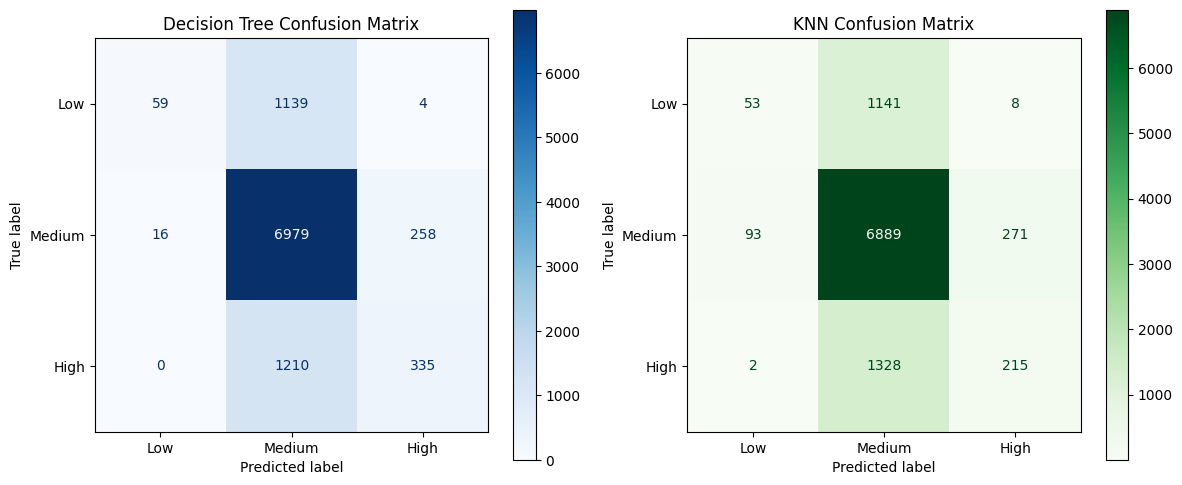

In [ ]:
labels = ['Low', 'Medium', 'High']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    labels=labels,
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title('Decision Tree Confusion Matrix')

ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_pred,
    labels=labels,
    cmap='Greens',
    ax=axes[1]
)
axes[1].set_title('KNN Confusion Matrix')

plt.tight_layout()
plt.show()

 ## Final Visualization 3 - Decision Tree Feature Importance

In [ ]:
preprocessor_fitted = decision_tree_model.named_steps['preprocessor']

encoded_cat_features = preprocessor_fitted.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(encoded_cat_features)

feature_importances = decision_tree_model.named_steps['classifier'].feature_importances_

importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

top_features = importance_df.head(10)
top_features

,Feature,Importance
22,Prompt_Engineering_Skill_Advanced,0.327571
18,Primary_Use_Case_Debugging/Troubleshooting,0.227188
1,Weekly_GenAI_Hours,0.168965
19,Primary_Use_Case_Direct_Answer_Generation,0.086140
24,Prompt_Engineering_Skill_Intermediate,0.067465
4,Traditional_Study_Hours,0.055319
0,Pre_Semester_GPA,0.041995
15,Year_of_Study_Senior,0.020382
27,Institutional_Policy_Strict_Ban,0.004454
12,Year_of_Study_Freshman,0.000520


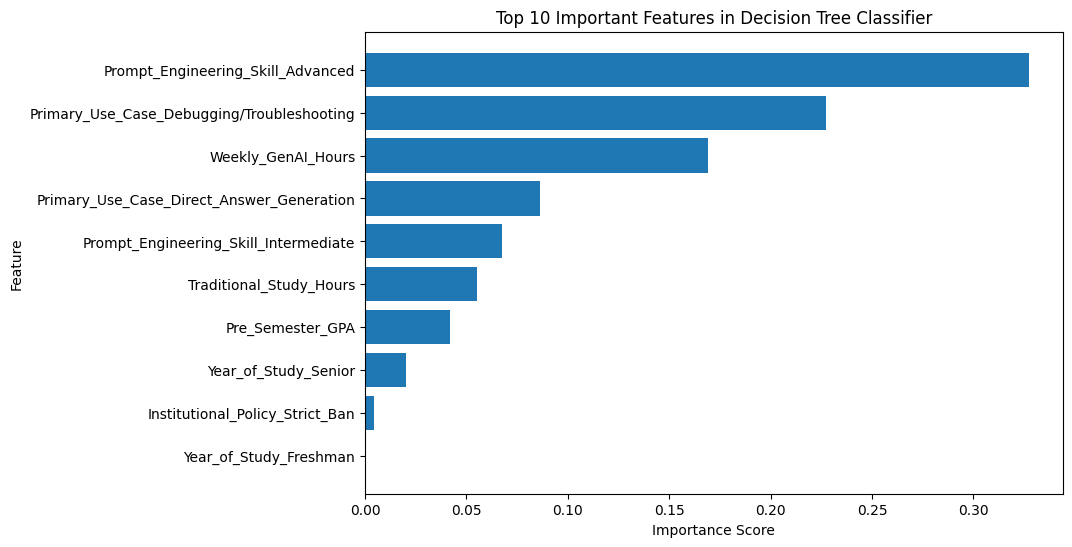

In [ ]:
plt.figure(figsize=(9, 6))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.title('Top 10 Important Features in Decision Tree Classifier')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.gca().invert_yaxis()
plt.show()

## Conclusion

In [ ]:
best_model = results.iloc[0]['Model']
best_accuracy = results.iloc[0]['Accuracy (%)']

print('Conclusion Summary')
print('------------------')
print(f'The best performing model was {best_model} with an accuracy of {best_accuracy:.2f}%.')
print('This project predicted student skill retention level as Low, Medium, or High based on Generative AI usage, study habits, and academic factors.')
print('Decision Tree is easier to interpret because it provides feature importance.')
print('KNN classifies students based on similarity to other students in the dataset.')
print('A limitation is that the target classes are not perfectly balanced, so balanced accuracy and confusion matrix should also be considered.')

Conclusion Summary
------------------
The best performing model was Decision Tree Classifier with an accuracy of 73.73%.
This project predicted student skill retention level as Low, Medium, or High based on Generative AI usage, study habits, and academic factors.
Decision Tree is easier to interpret because it provides feature importance.
KNN classifies students based on similarity to other students in the dataset.
A limitation is that the target classes are not perfectly balanced, so balanced accuracy and confusion matrix should also be considered.
